1. INSTALL DEPENDENCIES

2. CONFIGURE API KEYS

In [1]:
import os
from getpass import getpass

try:
  from dotenv import load_dotenv
  load_dotenv()
except Exception:
  pass

if not os.getenv("GROQ_API_KEY"):
    os.environ["GROQ_API_KEY"] = getpass(" Enter GROQ_API_KEY :")
if not os.getenv("TAVILY_API_KEY"):
    os.environ["TAVILY_API_KEY"] = getpass(" Enter TAVILY_API_KEY :")
if not os.getenv("PINECONE_API_KEY"):
    os.environ["PINECONE_API_KEY"] = getpass(" Enter PINECONE_API_KEY :")

print("GROQ_API_KEY configured:", bool(os.getenv("GROQ_API_KEY")))
print("TAVILY_API_KEY configured:", bool(os.getenv("TAVILY_API_KEY")))
print("PINECONE_API_KEY configured:", bool(os.getenv("PINECONE_API_KEY")))
        

GROQ_API_KEY configured: True
TAVILY_API_KEY configured: True
PINECONE_API_KEY configured: True


3. Load Real Documents
we will create our private knowledge base from a real web document:
https://docs.langchain.com/oss/python/langgraph/agentic-rag
this becomes our internal/private KB for the demo
the web fallback is separate. that means:

-> first source: indexed LangGraph documentation page
-> fallback source: live web search through tavily

In [2]:
from langchain_community.document_loaders import WebBaseLoader

SOURCE_URL = "https://docs.langchain.com/oss/python/langgraph/agentic-rag"

loader = WebBaseLoader(
    web_paths=(SOURCE_URL,),
    requests_kwargs={
        "headers":{
            "User-Agent": "Mozilla/5.0 Agentic-RAG-Industry-Demo"
        }
    },
)
raw_docs = loader.load()

print("Loaded documents:", len(raw_docs))
print("Source:" , raw_docs[0].metadata.get("source"))
print("\nPreview:\n")
print(raw_docs[0].page_content[:1500])

C:\Users\Minal\AppData\Local\Temp\ipykernel_5660\894226565.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import WebBaseLoader
USER_AGENT environment variable not set, consider setting it to identify your requests.


Loaded documents: 1
Source: https://docs.langchain.com/oss/python/langgraph/agentic-rag

Preview:

Build a custom RAG agent with LangGraph - Docs by LangChainDocumentation IndexFetch the complete documentation index at: /llms.txtUse this file to discover all available pages before exploring further.Skip to main contentDocs by LangChain home pageBuildSearch...⌘KAsk AIGitHubTry LangSmithTry LangSmithSearch...NavigationLangGraphBuild a custom RAG agent with LangGraphOverviewDeep AgentsManaged Deep AgentsLangChainLangGraphOpenWikiIntegrationsLearnReferenceContributePythonLearnTutorialsDeep AgentsData AnalysisDeep ResearchContent BuilderRAGLangChainDeep AgentSemantic searchSQL agentVoice agentMulti-agentSubagents: Personal assistantHandoffs: Customer supportRouter: Knowledge baseSkills: SQL assistantLangGraphCustom RAG agentCustom SQL agentConceptual overviewsLangChain vs. LangGraph vs. Deep AgentsProviders and modelsComponent architectureMemoryContextHuman-in-the-loopGraph APIFunctional AP

4. Split the Documents into Chunks

In [3]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
splitter = RecursiveCharacterTextSplitter(
    chunk_size = 1000,
    chunk_overlap =150,
    add_start_index = True,
)
chunks = splitter.split_documents(raw_docs)

print("Total Chunks:", len(chunks))
print("\nFirst Chunk Preview:\n")
print(chunks[0].page_content[:900])

Total Chunks: 28

First Chunk Preview:

Build a custom RAG agent with LangGraph - Docs by LangChainDocumentation IndexFetch the complete documentation index at: /llms.txtUse this file to discover all available pages before exploring further.Skip to main contentDocs by LangChain home pageBuildSearch...⌘KAsk AIGitHubTry LangSmithTry LangSmithSearch...NavigationLangGraphBuild a custom RAG agent with LangGraphOverviewDeep AgentsManaged Deep AgentsLangChainLangGraphOpenWikiIntegrationsLearnReferenceContributePythonLearnTutorialsDeep AgentsData AnalysisDeep ResearchContent BuilderRAGLangChainDeep AgentSemantic searchSQL agentVoice agentMulti-agentSubagents: Personal assistantHandoffs: Customer supportRouter: Knowledge baseSkills: SQL assistantLangGraphCustom RAG agentCustom SQL agentConceptual overviewsLangChain vs. LangGraph vs. Deep AgentsProviders and modelsComponent architectureMemoryContextHuman-in-the-loopGraph APIFunctional A


5.Create Free Local Embeddings

In [4]:
from langchain_huggingface import HuggingFaceEmbeddings

embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2",
    encode_kwargs = {"normalize_embeddings":True},
)

sample_vector = embeddings.embed_query("what is Agentic RAG?")
print("embedding dimensions:",len(sample_vector))

d:\Main Project\Agentic AI\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1386.37it/s]


embedding dimensions: 384


6. Create the Pinecone Vector Database
the embedding model used in this notebook 384-dimensional vectors, so the Pinecone index must use dimension 384.

In [5]:
from pinecone import Pinecone, ServerlessSpec
from langchain_pinecone import PineconeVectorStore
import time
import os

INDEX_NAME = "industry-agentic-rag-kb"
NAMESPACE = "langgraph-agentic-rag"

#connect to pinecone
pc = Pinecone(api_key=os.environ["PINECONE_API_KEY"])

#create the index only if it does not already exist
existing_indexes = [index_info["name"] for index_info in pc.list_indexes()]

if INDEX_NAME not in existing_indexes:
    pc.create_index(
        name=INDEX_NAME,
        dimension=384,
        metric="cosine",
        spec=ServerlessSpec(cloud="aws", region="us-east-1"),
    )

#wait until Pinecone reports the row index as ready.
while not pc.describe_index(INDEX_NAME).status["ready"]:
    time.sleep(1)
print("Pinecone index ready:",INDEX_NAME)
#upload the document chunks and create and create the langchain vector store.
vectorstore = PineconeVectorStore.from_documents(
    documents=chunks,
    embedding=embeddings,
    index_name=INDEX_NAME,
    namespace=NAMESPACE,
)
retriever = vectorstore.as_retriever(
    search_kwargs={
        "k" : 4,
        "namespace" : NAMESPACE,
    }
)
print("Pinecone vector database and retriever are ready.")

Pinecone index ready: industry-agentic-rag-kb
Pinecone vector database and retriever are ready.


In [6]:
#load Existing Index
from pinecone import Pinecone
from langchain_pinecone import PineconeVectorStore
import os 
INDEX_NAME = "industry-agentic-rag-kb"
NAMESPACE = "langgraph-agentic-rag"

#Connect to Pinecone
pc = Pinecone(api_key=os.environ["PINECONE_API_KEY"])

#Load existing Pinecone index
index = pc.Index(INDEX_NAME)

#connect existing index with Langchain
vectorstore = PineconeVectorStore(
    index=index,
    embedding=embeddings,
    namespace=NAMESPACE,
)

#create retriever
retriever = vectorstore.as_retriever(
    search_kwargs ={
        "k":4,
        "namespace":NAMESPACE,
    }
)

print("Existing Pinecone index loaded:", INDEX_NAME)

Existing Pinecone index loaded: industry-agentic-rag-kb


7. Test Private KB Retrieval

In [7]:
test_question = "what happens if retrieved documents are not relevant in Agentic Rag?"
kb_docs = retriever.invoke(test_question)

for i,doc in enumerate(kb_docs,1):
    print(f"\n--- KB RESULT {i} ---")
    print("Source:", doc.metadata.get("source"))
    print(doc.page_content[:700])



--- KB RESULT 1 ---
Source: https://docs.langchain.com/oss/python/langgraph/agentic-rag
Build a custom RAG agent with LangGraph - Docs by LangChainDocumentation IndexFetch the complete documentation index at: /llms.txtUse this file to discover all available pages before exploring further.Skip to main contentDocs by LangChain home pageBuildSearch...⌘KAsk AIGitHubTry LangSmithTry LangSmithSearch...NavigationLangGraphBuild a custom RAG agent with LangGraphOverviewDeep AgentsManaged Deep AgentsLangChainLangGraphOpenWikiIntegrationsLearnReferenceContributePythonLearnTutorialsDeep AgentsData AnalysisDeep ResearchContent BuilderRAGLangChainDeep AgentSemantic searchSQL agentVoice agentMulti-agentSubagents: Personal assistantHandoffs: Customer supportRouter: Knowledge baseSkills: SQL as

--- KB RESULT 2 ---
Source: https://docs.langchain.com/oss/python/langgraph/agentic-rag
Build a custom RAG agent with LangGraph - Docs by LangChainDocumentation IndexFetch the complete documentation index at: 

8. Initialize Groq LLM

In [8]:
import langchain_groq
from langchain_groq import ChatGroq

#Replace this model if your Groq dashboard shows a differnet available model
llm = ChatGroq(
    model = "openai/gpt-oss-20b",
    temperature=0,
)
print(llm.invoke("Explain Agentic RAG in one sentence.").content)

Agentic RAG is a retrieval‑augmented generation framework in which an autonomous agent actively queries, selects, and incorporates relevant external documents on the fly to inform and improve its generated responses.


_9._ #Initialize Tavily Web Search
##Tavily will be used only when the private knowledge base is insufficient.
###This is important because we do not want to send every private/company question to the public web.

In [9]:
from langchain_tavily import TavilySearch
web_search = TavilySearch(
    max_results = 5,
    topic = "general",
    include_answer = True,
    include_raw_content=False,
)
print("Tavily search tool ready.")

Tavily search tool ready.


10. Define structured Decisions


we need reliable yes/no or route outputs from the LLM.

structured outputs help avoid parsing messy natural language

In [10]:
from typing import List,Literal,Optional
from typing_extensions import TypedDict
from pydantic import BaseModel,Field
from langchain_core.documents import Document

class RouteDecision(BaseModel):
    route: Literal["kb","direct"] = Field(
        description="Use kb for questions needing Agentic RAG docs; direct for greetings/simple chat."
    )
class EvidenceGrade(BaseModel):
    grade: Literal["good","weak"] = Field(
        description="good means evidence can answer the questions; weak means not enough evidence"
    )
class AgentState(TypedDict):
    question: str
    current_query:str
    kb_docs:List[Document]
    web_results:str
    kb_grade:str
    web_grade:str
    answer:str
    source_used:str
    retry_count:int

11. Node1--Route the question

the router decides:
.kb : use private knowledge base
.direct : answer without retrieval

in a real company assistant, this step may also route between many sources :HR docs, finance docs,product docs,SQL database,web search ,tec.

In [41]:
router_llm = llm.with_structured_output(RouteDecision,method="json_mode")

def route_question(state: AgentState):
    question = state["question"]

    decision = router_llm.invoke(f'''you are a router for an Agentic RAG assistant.
    Route to "kb" if the user asks about:
    - Agentic RAG
    - LangGraph Agentic RAG workflow
    - retrieval grading
    - query rewriting 
    - RAG architecture
    - retriever tools
    - web fallback in RAG

    Route to "direct" only for greetings, thanks, or very simple conversation.

    Question:
    {question}

    Return your response as valid JSON.
    Example:
    {{"route": "kb}}
    ''')

    print("[Router]",decision.route)
    return {
        "current_query": question,
        "source_used":decision.route,
    }
def route_after_router(state : AgentState) -> Literal["retrieve_kb","direct_answer"]:
    if state["source_used"] == "kb":
        return "retrieve_kb"
    return "direct_answer"

12. Node 2 - Retrieve from the Private KB

In [42]:
def retrieve_kb(state: AgentState):
    query = state["current_query"]
    docs = retriever.invoke(query)

    print(f"[KB Retriever] Query: {query}")
    print(f"[KB Retriever] Retrieved: {len(docs)} chunks")

    return {"kb_docs" : docs}

13. Node3 - Grade Private KB Evidence

this is the key step that decides whether we can answer from the private KB or need web fallback.

In [43]:
kb_grader_llm = llm.with_structured_output(EvidenceGrade, method="json_mode")

def grade_kb_evidence(state:AgentState):
    question = state["question"]

    context = "\n\n".join(
        f"Source: {doc.metadata.get('source')}\n{doc.page_content}"
        for doc in state["kb_docs"]
    )
    grade = kb_grader_llm.invoke(f'''
 you are an evidence grader.

 Question:
 {question}

 Private KB evidence:
 {context}

Can this private KB evidence answer the question?
Return "good" if it can answer.
Return "weak" if it cannot answer or is incomplete.

Return your response as valid JSON.
Example:
{{"grade":"good"}}
''') 
    print("[KB Grader]",grade.grade)

    return {"kb_grade":grade.grade}

MAX_RETRIES = 1

def decide_after_kb_grade(state: AgentState)->Literal["generate_from_kb","search_web"]:
    if state["kb_grade"] == "good":
        return "generate_from_kb"
    return "search_web"

14. Node 4 - Tavily Web Search Fallback


This node runs only when the private KB evidence is weak.
WE Search the web using original question, or the current rewritten query if a rewrite already happened.

In [69]:
def search_web(state: AgentState):
    query = state["current_query"]
    print(f"[Tavily Search] Query: {query}")

    result = web_search.invoke({"query":query})

    #Tavily can return dict/list structures depending on package version.
    #Convert it into readable text for grading and generation.

    if isinstance(result, dict):
        answer = result.get("answer", "")
        results = result.get("results",[])
        lines = []
        if answer:
            lines.append(f"Tavily answer: {answer}")

        for item in results:
            title = item.get("title", "")
            url = item.get("url", "")
            content = item.get("content", "")
            lines.append(f"Title: {title}\nURL: {url}\nContent: {content}")

        web_text = "\n\n".join(lines) if lines else str(result)
    else:
        web_text = str(result)
    print("[Tavily Search] Result Characters:", len(web_text))

    return {
        "web_results":web_text,
        "Source_used":"web",
    }

15. Node 5 - Grade Web Evidence

In [70]:
web_grader_llm = llm.with_structured_output(EvidenceGrade, method="json_mode")

def grade_web_evidence(state:AgentState):
    question = state["question"]
    web_results = state["web_results"]

    grade = web_grader_llm.invoke(f'''
you are an evidence grader.

Question:
{question}

web search evidence:
{web_results}

can this web evidence answer the question?
Return "good" if it can answer.
Return "weak" if it cannot answer or is incomplete.

Return your response as valid JSON.
Example:
{{"grade":"good"}}
''')
    print("[Web Grader]", grade.grade)
    return {"web_grade":grade.grade}
MAX_RETRIES = 1

def decide_after_web_grade(state:AgentState) -> Literal["generate_from_web","rewrite_query","answer_insufficient"]:
    if state["web_grade"] == "good":
        return "generate_from_web"
    if state["retry_count"] < MAX_RETRIES:
        return "rewrite_query"

    return "answer_insufficient"

16. Node 6 - Rewrite the Query

if both KB and web evidence are weak , we rewrite once and then try the KB again.
Why back to KB first?
Because the rewritten query may help retrieve better private evidence before relying on web search again.

In [71]:
from langchain_core.messages import HumanMessage

def rewrite_query(state: AgentState):
    question = state["question"]
    retry_count = state["retry_count"]+1

    rewritten = llm.invoke(f'''
Rewrite the question for better retrieval and web search .
Rule:
- PREserve original intent.
- Make it specific and search-friendly.
- Do not answer.
- Return only the rewritten query.

Original question:
{question}
''').content.strip()
    print("[Rewriter]",rewritten)

    return {
        "current_query": rewritten,
        "retry_count": retry_count,
    }



17. Node 7 - Generate from Private KB

In [72]:
def generate_from_kb(state: AgentState):
    question = state["question"]

    context = "\n\n".join(
        f"[KB Source: {doc.metadata.get('source')}]\n{doc.page_content}"
        for doc in state["kb_docs"]
    )

    answer = llm.invoke(f'''
You are a technical instructor.

Answer using only the private KB context.

Rules:
- Beginner-friendly explanation.
- Do not invent unsupported details.
- Mention that the answer is based on the private KB.
- Include source type: Private KB.

Question:
{question}
''').content

    return {
        "answer": answer,
        "source_used": "private_kb",
        
    }

18. Node 8 - Generate from Web Search

In [73]:
def generate_from_web(state: AgentState):
    question = state["question"]
    web_context = state["web_results"]

    answer = llm.invoke(f'''
you are a technical instructor.
the private KB was insufficient , so web search was used.

Answer using ONLY the web search context.

Rules:
-Beginner-friendly explanation.
-Do not invent unsupported details.
-Mention that the answer is based on Tavily web search.
-Include source type: Web Search.
-If URLs are present in context , include the most useful URLs.
Question:
{question}

Web search context:
{web_context}
''').content

    return {
        "answer": answer,
        "source_used": "web_search",
        
    }

19. Node 9 - Direct Answer

In [74]:
def direct_answer(state: AgentState):
    question = state["question"]

    answer = llm.invoke(f'''
Respond briefly and naturally.
Message:
{question}
''').content

    return {
        "answer": answer,
        "source_used":"direct",
    }


20. Node 10-Insufficient Evidence Answer

In [75]:
def answer_insufficient(state: AgentState):
    answer = (
        "I could not find enough reliable evidence in the private knowlwdge base"
        "or the web search results to answer this confidently."
        "Please provide more specific documents or rephrase the question."
    )
    return {
        "answer": answer,
        "source_used": "insufficient_evidence",
    }

21. Build the LangGraph Workflow

In [76]:
from langgraph.graph import StateGraph, START,END

workflow = StateGraph(AgentState)

workflow.add_node("route_question", route_question)
workflow.add_node("retrieve_kb", retrieve_kb)
workflow.add_node("grade_kb_evidence", grade_kb_evidence)
workflow.add_node("search_web", search_web)
workflow.add_node("grade_web_evidence", grade_web_evidence)
workflow.add_node("rewrite_query", rewrite_query)
workflow.add_node("generate_from_kb", generate_from_kb)
workflow.add_node("generate_from_web", generate_from_web)
workflow.add_node("direct_answer", direct_answer)
workflow.add_node("answer_insufficient", answer_insufficient)

workflow.add_edge(START, "route_question")

workflow.add_conditional_edges(
    "route_question",
    route_after_router,
    {
        "retrieve_kb":"retrieve_kb",
        "direct_answer":"direct_answer",
    }
)

# MISSING EDGE — add this
workflow.add_edge("retrieve_kb", "grade_kb_evidence")

# Web search path
workflow.add_edge("search_web", "grade_web_evidence")

workflow.add_conditional_edges(
    "grade_kb_evidence",
    decide_after_kb_grade,
    {
        "generate_from_kb": "generate_from_kb",
        "search_web": "search_web",
        "rewrite_query": "rewrite_query",
        "answer_insufficient": "answer_insufficient",
    },
)

workflow.add_conditional_edges(
    "grade_web_evidence",
    decide_after_web_grade,
    {
        "generate_from_web":"generate_from_web",
        "rewrite_query":"rewrite_query",
        "answer_insufficient":"answer_insufficient",
    },
)

workflow.add_edge("rewrite_query", "retrieve_kb")
workflow.add_edge("generate_from_kb", END)
workflow.add_edge("generate_from_web", END)
workflow.add_edge("direct_answer",END)
workflow.add_edge("answer_insufficient", END)

app = workflow.compile()

print("Industry-style Agentic RAG graph compiled.")
 



Industry-style Agentic RAG graph compiled.


22. Visualize the Graph

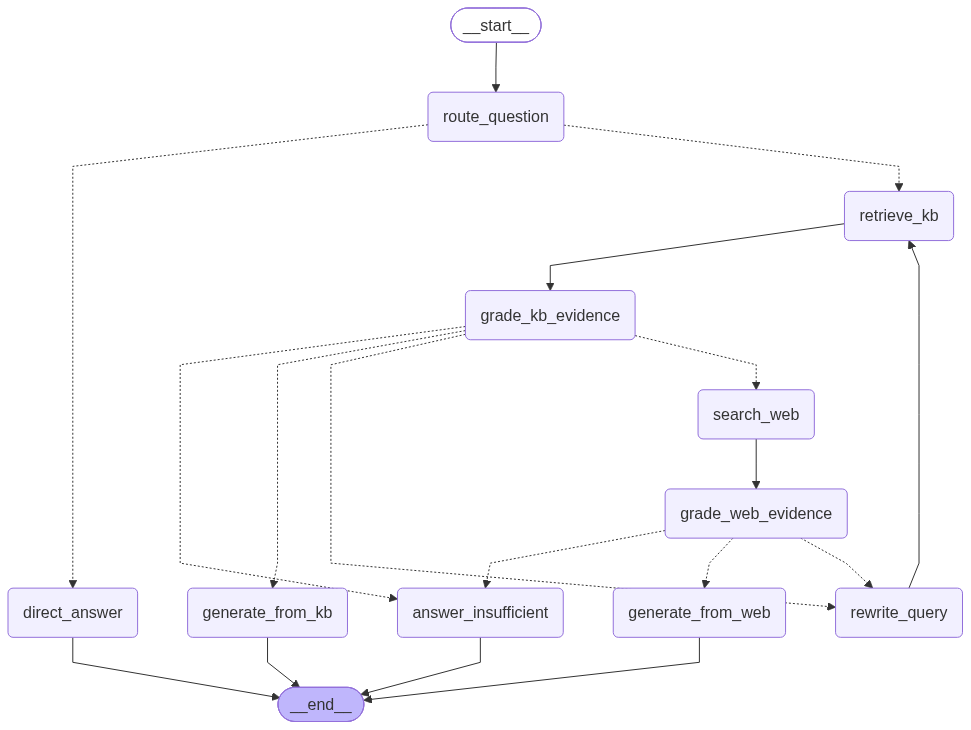

In [77]:
from IPython.display import Image, display

try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Graph visualization is optional. The graph can still run.")
    print("Reason:", e)
    

23. Helper Function

In [78]:
def ask_agent(question: str):
    initial_state: AgentState = {
        "question": question,
        "current_query":question,
        "kb_docs":[],
        "web_results":"",
        "kb_grade":"",
        "web_grade":"",
        "answer":"",
        "source_used":"",
        "retry_count":0,
    }

    result = app.invoke(initial_state)

    print("\n" + "=" * 90)
    print("Question:")
    print(question)
    print("\nSOURCE USED:")
    print(result["source_used"])
    print("\nFINAL ANSWER:")
    print(result["answer"])
    print("="*90)

    return result

24. Demo 1 - Answer from Private KB

In [79]:
result = ask_agent(
    "In Agentic RAG, what happens when retrieved documents are not relevant?"
)

[Router] kb
[KB Retriever] Query: In Agentic RAG, what happens when retrieved documents are not relevant?
[KB Retriever] Retrieved: 4 chunks
[KB Grader] weak
[Tavily Search] Query: In Agentic RAG, what happens when retrieved documents are not relevant?
[Tavily Search] Result Characters: 7908
[Web Grader] good

Question:
In Agentic RAG, what happens when retrieved documents are not relevant?

SOURCE USED:
web_search

FINAL ANSWER:
**Answer (based on a Tavily web search)**  

When an Agentic RAG system pulls documents that turn out to be irrelevant, it doesn’t just give up or hallucinate. Instead, it uses a built‑in “self‑check” and “re‑search” loop:

1. **Reflection Engine** – The agent first evaluates the retrieved documents with questions like *“Is this relevant?”* and *“Is it grounded in the source?”*. If the confidence is low, the system flags the result as a *re‑query signal*.

2. **Re‑retrieval Loop** – Triggered by that signal, the agent reformulates its query (sometimes changing

25. Demo 2 - Web Search Fallback

In [ ]:
result = ask_agent(
    "What is Tavily"
)